# 04 · Predicting collision severity

**Question:** *Given that a collision happens*, how likely is it that someone is **killed or seriously injured (KSI)**, and which conditions push that risk up or down?

This model does **not** predict whether a crash will happen. It only predicts how bad a crash is likely to be, from things known at the scene: time, place, road, conditions, and who was involved.

**Approach**
1. Build features a person could pick in a "what-if" tool (all categories or yes/no flags).
2. **Split by time:** train on 2021–2024 and test on 2025. This mimics using the model on future data and is stricter than a random split.
3. Compare an interpretable **logistic regression** with a **gradient-boosted tree** model.
4. Check discrimination (ROC AUC), calibration (are the probabilities honest?) and lift.
5. Export the chosen model as plain JSON coefficients for the dashboard. No pickle files, so it's robust to deploy.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEAN, FIG, MODELS = ROOT / "data/clean", ROOT / "report/figures", ROOT / "models"
MODELS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
RED, BLUE, GREY = "#dc2626", "#2563eb", "#9ca3af"

c = pd.read_parquet(CLEAN / "collisions.parquet")
print(f"{len(c):,} collisions, KSI rate {c.is_ksi.mean():.1%}")

8,375 collisions, KSI rate 20.9%


## 1. Features
Each feature is grouped into a few clear options, the same ones the dashboard will offer. Rare categories are merged so the model doesn't learn from a handful of cases.

We deliberately **leave out** anything that's a *result* of the crash's severity, such as number of casualties, KSI casualty counts and adjusted severity. Using those would be *leakage*: the model would be cheating.

In [2]:
def build_features(d):
    f = pd.DataFrame(index=d.index)
    f["time_band"] = d.time_band.astype(str)
    f["day_type"] = np.where(d.is_weekend, "Weekend", "Weekday")
    f["district"] = d.district
    f["speed_limit"] = d.speed_limit.astype("Int64").astype(str) + " mph"
    f["road_class"] = d.first_road_class_label.replace({"A(M)": "Motorway"})
    f["area"] = d.urban_or_rural_area_label.replace({"Unallocated": "Urban"})
    f["light"] = d.light_conditions_label.map({
        "Daylight": "Daylight", "Darkness - lights lit": "Dark, street lights on",
        "Darkness - lighting unknown": "Dark, street lights on",
        "Darkness - no lighting": "Dark, no street lights", "Darkness - lights unlit": "Dark, no street lights"})
    f["weather"] = np.select([d.weather_conditions_label.str.startswith("Fine"),
                              d.weather_conditions_label.str.startswith("Raining")], ["Fine", "Rain"], "Other / unknown")
    f["surface"] = np.select([d.road_surface_conditions_label.eq("Dry"),
                              d.road_surface_conditions_label.eq("Wet or damp")], ["Dry", "Wet"], "Ice, snow, flood / unknown")
    f["junction"] = d.junction_detail_label.map({
        "Not at junction or within 20 metres": "Not at a junction", "T or staggered junction": "T-junction",
        "Crossroads": "Crossroads"}).fillna("Other / unknown junction")
    f["vehicles"] = np.select([d.number_of_vehicles.eq(1), d.number_of_vehicles.eq(2)], ["1 (single vehicle)", "2"], "3 or more")
    flags = {
        "pedestrian": d.pedestrian_casualties > 0,
        "cyclist": d.involves_cycle | (d.cyclist_casualties > 0),
        "motorcycle": d.involves_motorcycle | (d.motorcyclist_casualties > 0),
        "hgv": d.involves_hgv, "bus": d.involves_bus, "escooter": d.involves_escooter,
        "young_driver": d.involves_young_driver, "older_driver": d.involves_older_driver,
    }
    for k, v in flags.items():
        f[k] = np.where(v, "Yes", "No")
    return f

data = c.dropna(subset=["speed_limit"])
X, y, years = build_features(data), data.is_ksi.astype(int), data.year
FEATURES = list(X.columns)
assert X.notna().all().all(), X.isna().sum()[X.isna().sum() > 0]

train, test = years <= 2024, years == 2025
X_tr, X_te, y_tr, y_te = X[train], X[test], y[train], y[test]
print(f"Train 2021–24: {len(X_tr):,} rows ({y_tr.mean():.1%} KSI) · Test 2025: {len(X_te):,} rows ({y_te.mean():.1%} KSI)")
X.head()

Train 2021–24: 6,839 rows (20.6% KSI) · Test 2025: 1,536 rows (22.7% KSI)


,time_band,day_type,district,speed_limit,road_class,area,light,weather,surface,junction,vehicles,pedestrian,cyclist,motorcycle,hgv,bus,escooter,young_driver,older_driver
0,Daytime (10–15),Weekday,St Albans,30 mph,Unclassified,Urban,Daylight,Fine,Dry,Not at a junction,1 (single vehicle),Yes,No,No,No,No,No,Yes,No
1,Evening peak (16–18),Weekday,St Albans,60 mph,Unclassified,Rural,"Dark, street lights on",Rain,Wet,Not at a junction,2,No,Yes,No,No,No,No,No,No
2,Daytime (10–15),Weekend,East Hertfordshire,30 mph,Unclassified,Urban,Daylight,Fine,Wet,T-junction,3 or more,No,No,No,No,No,No,No,No
3,Daytime (10–15),Weekend,Watford,30 mph,Unclassified,Urban,Daylight,Fine,Dry,Not at a junction,3 or more,No,No,No,No,No,No,No,No
4,Daytime (10–15),Weekend,Stevenage,30 mph,Unclassified,Urban,Daylight,Fine,Wet,Not at a junction,2,No,No,No,No,No,No,No,No


## 2. Models
**Logistic regression:** each option gets one number (a coefficient). That makes it easy to explain, and easy to run in the dashboard. `C` sets how strongly it's regularised (pulled towards zero) and is chosen by 5-fold cross-validation on the training years.

**Gradient boosting:** a flexible tree model that can capture interactions (e.g. *dark AND rural*). We use it as a benchmark: if it's much better, the simple model is missing something.

In [3]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)

logit = GridSearchCV(
    Pipeline([("ohe", OneHotEncoder(handle_unknown="ignore")),
              ("lr", LogisticRegression(max_iter=2000))]),
    {"lr__C": [0.01, 0.03, 0.1, 0.3, 1, 3]}, scoring="roc_auc", cv=cv).fit(X_tr, y_tr)

gbm = GridSearchCV(
    Pipeline([("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
              ("gb", HistGradientBoostingClassifier(categorical_features=[True] * len(FEATURES), random_state=42))]),
    {"gb__learning_rate": [0.03, 0.1], "gb__max_depth": [3, 5], "gb__max_iter": [150, 300],
     "gb__l2_regularization": [0, 1]}, scoring="roc_auc", cv=cv).fit(X_tr, y_tr)

print("Logistic best C:", logit.best_params_["lr__C"], f"· CV AUC {logit.best_score_:.3f}")
print("GBM best params:", gbm.best_params_, f"· CV AUC {gbm.best_score_:.3f}")

Logistic best C: 1 · CV AUC 0.706
GBM best params: {'gb__l2_regularization': 1, 'gb__learning_rate': 0.03, 'gb__max_depth': 3, 'gb__max_iter': 300} · CV AUC 0.701


## 3. How good is it on unseen 2025 data?

| Metric | Meaning | Baseline (guessing) |
|---|---|---|
| **ROC AUC** | Chance the model ranks a random KSI crash above a random non-KSI crash | 0.50 |
| **PR AUC** | Precision/recall for finding KSI crashes | = KSI rate |
| **Brier score** | Average squared error of the probabilities (lower is better) | always predicting the average |

In [4]:
p_base = np.full(len(y_te), y_tr.mean())
preds = {"Logistic regression": logit.predict_proba(X_te)[:, 1], "Gradient boosting": gbm.predict_proba(X_te)[:, 1]}

rows = [{"model": "Baseline (average rate)", "ROC AUC": 0.5, "PR AUC": y_te.mean(), "Brier": brier_score_loss(y_te, p_base)}]
for name, p in preds.items():
    rows.append({"model": name, "ROC AUC": roc_auc_score(y_te, p), "PR AUC": average_precision_score(y_te, p),
                 "Brier": brier_score_loss(y_te, p)})
metrics = pd.DataFrame(rows).set_index("model").round(3)
metrics

,ROC AUC,PR AUC,Brier
model,,,
Baseline (average rate),0.500,0.227,0.176
Logistic regression,0.649,0.355,0.168
Gradient boosting,0.647,0.360,0.167


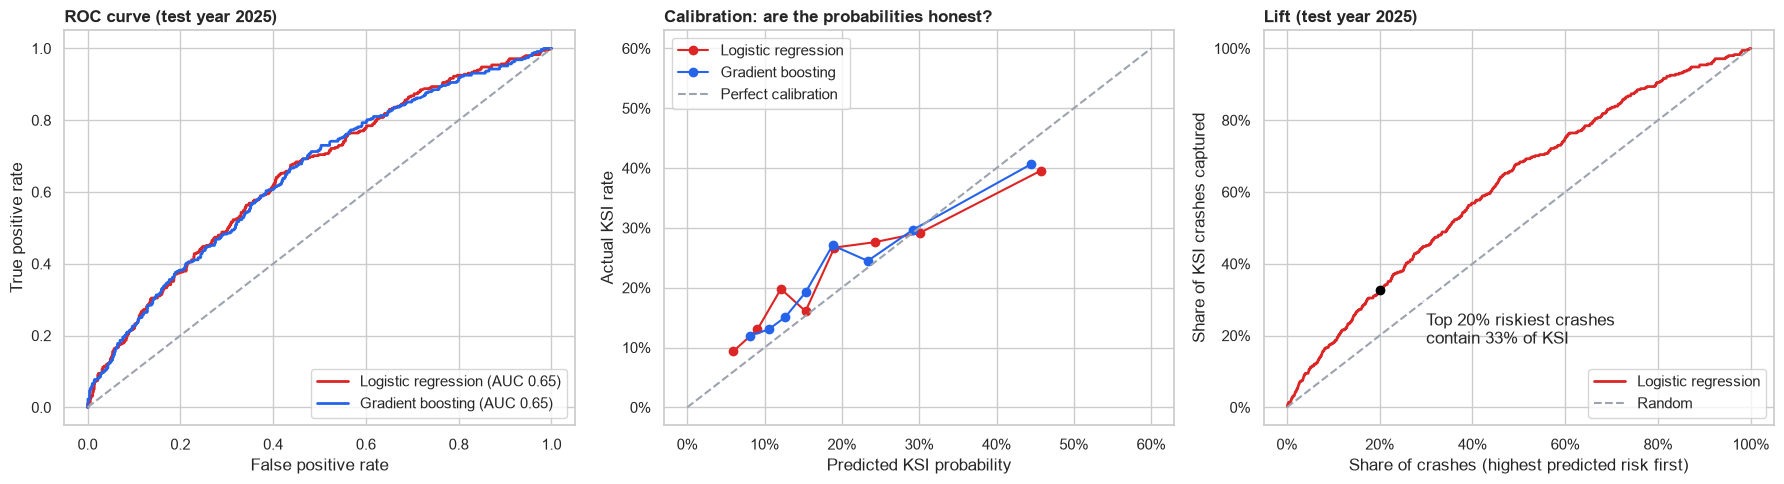

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for (name, p), col in zip(preds.items(), [RED, BLUE]):
    fpr, tpr, _ = roc_curve(y_te, p)
    ax[0].plot(fpr, tpr, color=col, lw=2, label=f"{name} (AUC {roc_auc_score(y_te, p):.2f})")
    frac, mean_p = calibration_curve(y_te, p, n_bins=8, strategy="quantile")
    ax[1].plot(mean_p, frac, "o-", color=col, label=name)
ax[0].plot([0, 1], [0, 1], "--", color=GREY); ax[0].set(xlabel="False positive rate", ylabel="True positive rate")
ax[0].set_title("ROC curve (test year 2025)", loc="left", fontweight="bold"); ax[0].legend(loc="lower right")
ax[1].plot([0, .6], [0, .6], "--", color=GREY, label="Perfect calibration")
ax[1].set(xlabel="Predicted KSI probability", ylabel="Actual KSI rate")
ax[1].xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[1].set_title("Calibration: are the probabilities honest?", loc="left", fontweight="bold"); ax[1].legend()

# Lift: share of KSI captured when ranking crashes by predicted risk
p = preds["Logistic regression"]
order = np.argsort(-p); cum = np.cumsum(y_te.values[order]) / y_te.sum(); share = np.arange(1, len(p) + 1) / len(p)
ax[2].plot(share, cum, color=RED, lw=2, label="Logistic regression"); ax[2].plot([0, 1], [0, 1], "--", color=GREY, label="Random")
top20 = cum[int(.2 * len(p)) - 1]
ax[2].scatter([.2], [top20], color="black", zorder=5); ax[2].annotate(f"Top 20% riskiest crashes\ncontain {top20:.0%} of KSI", (.2, top20),
                                                                  xytext=(.3, top20 - .15), arrowprops=dict(arrowstyle="->"))
ax[2].xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax[2].yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[2].set(xlabel="Share of crashes (highest predicted risk first)", ylabel="Share of KSI crashes captured")
ax[2].set_title("Lift (test year 2025)", loc="left", fontweight="bold"); ax[2].legend(loc="lower right")
plt.tight_layout(); fig.savefig(FIG / "14_model_performance.png", dpi=150, bbox_inches="tight")

### Which model to use?
If gradient boosting isn't clearly better (more than ~0.02 AUC), we prefer logistic regression. It's transparent, every effect can be explained in plain English, and it runs in the dashboard from a small JSON file.

In [6]:
gap = metrics.loc["Gradient boosting", "ROC AUC"] - metrics.loc["Logistic regression", "ROC AUC"]
CHOSEN = "Logistic regression" if gap < 0.02 else "Gradient boosting"
print(f"AUC gap (GBM − logistic): {gap:+.3f} → using {CHOSEN} for the dashboard")

AUC gap (GBM − logistic): -0.002 → using Logistic regression for the dashboard


## 4. What drives severity?
### Permutation importance
We shuffle one feature at a time on the 2025 test data and measure how much the AUC drops. A big drop means the model relies on that feature.

,feature,AUC drop,sd
0,motorcycle,0.0585,0.0087
1,cyclist,0.0470,0.0054
2,vehicles,0.0205,0.0083
3,pedestrian,0.0177,0.0065
4,speed_limit,0.0108,0.0057
5,time_band,0.0103,0.0036
6,escooter,0.0097,0.0023
7,road_class,0.0064,0.0041
8,surface,0.0051,0.0032
9,district,0.0024,0.0029


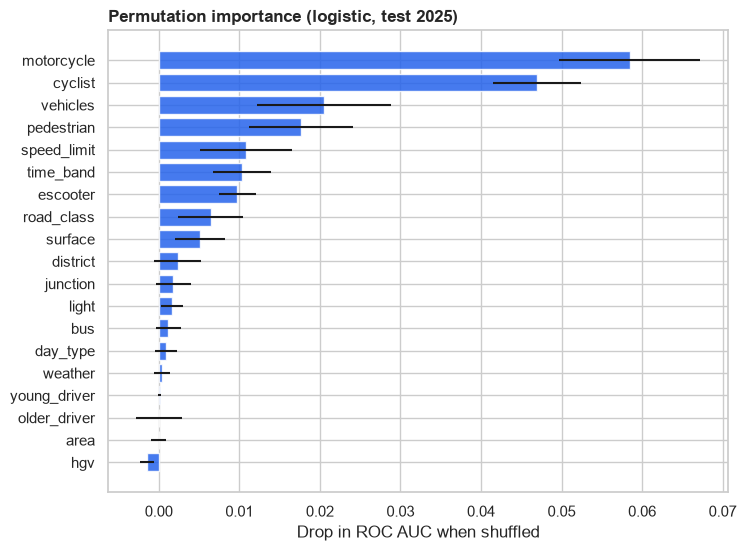

In [7]:
pi = permutation_importance(logit.best_estimator_, X_te, y_te, scoring="roc_auc", n_repeats=30, random_state=42)
imp = pd.DataFrame({"feature": FEATURES, "AUC drop": pi.importances_mean, "sd": pi.importances_std}).sort_values("AUC drop")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(imp.feature, imp["AUC drop"], xerr=imp.sd, color=BLUE, alpha=.85)
ax.set_title("Permutation importance (logistic, test 2025)", loc="left", fontweight="bold"); ax.set_xlabel("Drop in ROC AUC when shuffled")
fig.savefig(FIG / "15_feature_importance.png", dpi=150, bbox_inches="tight")
imp.sort_values("AUC drop", ascending=False).round(4).reset_index(drop=True)

### Effect of each option (odds ratios)
To make effects readable, each option is compared with the **average crash**: its coefficient minus the frequency-weighted average coefficient of its feature.

An **odds ratio of 2** means "this option doubles the odds of KSI compared with an average crash"; 0.5 means it halves them. These are **associations** after accounting for the other features. They are not proof of cause.

,label,odds_ratio,share_of_train
0,escooter: Yes,3.91,0.01
1,motorcycle: Yes,3.73,0.14
2,cyclist: Yes,2.93,0.11
3,bus: Yes,2.13,0.01
4,pedestrian: Yes,2.12,0.14
5,vehicles: 1 (single vehicle),1.86,0.21
6,time_band: Night (00–05),1.86,0.04
7,speed_limit: 70 mph,1.63,0.16
8,speed_limit: 60 mph,1.50,0.11
9,road_class: B,1.41,0.12


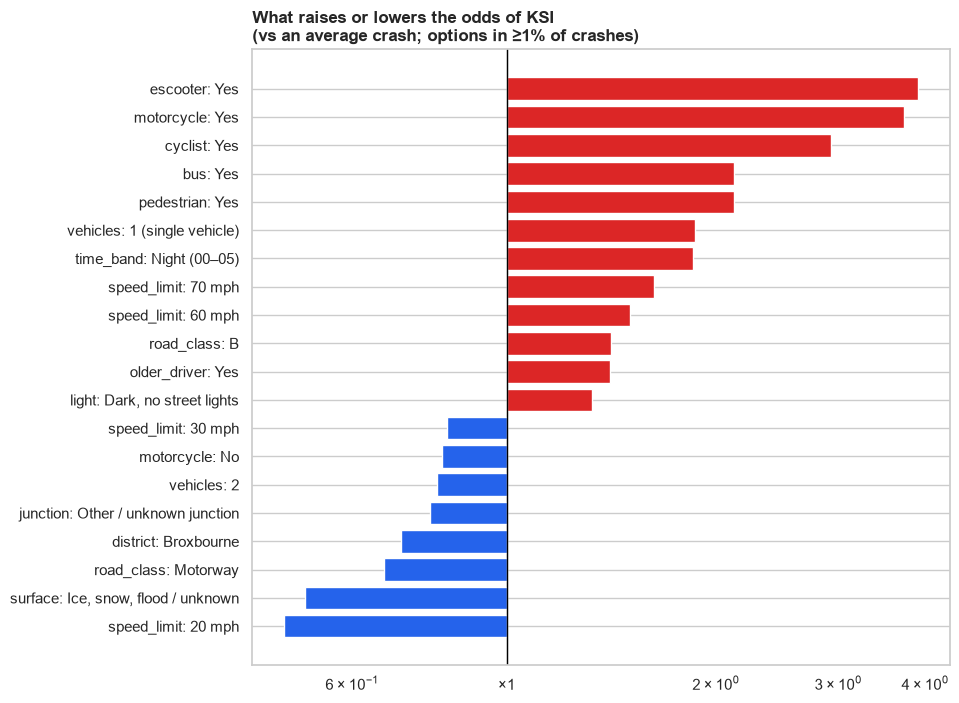

In [8]:
ohe = logit.best_estimator_.named_steps["ohe"]; lr = logit.best_estimator_.named_steps["lr"]
coef = pd.Series(lr.coef_[0], index=ohe.get_feature_names_out(FEATURES))
freq = pd.concat([X_tr[f].value_counts(normalize=True).rename(lambda v, f=f: f"{f}_{v}") for f in FEATURES])

effects = []
for f, cats in zip(FEATURES, ohe.categories_):
    names = [f"{f}_{v}" for v in cats]
    mean_coef = float((coef[names] * freq.reindex(names).fillna(0)).sum())
    for v, n in zip(cats, names):
        effects.append({"feature": f, "option": v, "coef": coef[n], "vs_average": coef[n] - mean_coef,
                        "odds_ratio": np.exp(coef[n] - mean_coef), "share_of_train": freq.get(n, 0)})
effects = pd.DataFrame(effects)

show = effects[effects.share_of_train >= 0.01].copy()
show["label"] = show.feature + ": " + show.option
show = pd.concat([show.nlargest(12, "odds_ratio"), show.nsmallest(8, "odds_ratio")]).drop_duplicates().sort_values("odds_ratio")
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(show.label, show.odds_ratio - 1, left=1, color=np.where(show.odds_ratio > 1, RED, BLUE))
ax.axvline(1, color="black", lw=1); ax.set_xscale("log")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"×{v:g}"))
ax.set_title("What raises or lowers the odds of KSI\n(vs an average crash; options in ≥1% of crashes)", loc="left", fontweight="bold")
fig.savefig(FIG / "16_odds_ratios.png", dpi=150, bbox_inches="tight")
show[["label", "odds_ratio", "share_of_train"]].sort_values("odds_ratio", ascending=False).round(2).reset_index(drop=True)

## 5. Example scenarios

In [9]:
def scenario(**kw):
    base = X_tr.mode().iloc[0].to_dict()
    base.update(kw)
    return pd.DataFrame([base])[FEATURES]

examples = {
    "Typical: weekday daytime, 30 mph urban, 2 cars": scenario(),
    "Night, 60 mph rural, no street lights, single vehicle": scenario(time_band="Night (00–05)", speed_limit="60 mph", area="Rural",
                                                                     light="Dark, no street lights", vehicles="1 (single vehicle)"),
    "Motorcycle on 60 mph rural road, weekend": scenario(motorcycle="Yes", speed_limit="60 mph", area="Rural", day_type="Weekend"),
    "Pedestrian hit, 30 mph, evening, dark (lit)": scenario(pedestrian="Yes", vehicles="1 (single vehicle)", light="Dark, street lights on",
                                                             time_band="Evening (19–21)"),
    "Motorway, daytime, 3+ vehicles": scenario(road_class="Motorway", speed_limit="70 mph", vehicles="3 or more"),
}
pd.DataFrame({"KSI probability": {k: logit.predict_proba(v)[0, 1] for k, v in examples.items()}}) \
  .assign(**{"× average": lambda d: d["KSI probability"] / y_tr.mean()}).style.format({"KSI probability": "{:.0%}", "× average": "{:.1f}×"})

,KSI probability,× average
"Typical: weekday daytime, 30 mph urban, 2 cars",7%,0.3×
"Night, 60 mph rural, no street lights, single vehicle",48%,2.3×
"Motorcycle on 60 mph rural road, weekend",45%,2.2×
"Pedestrian hit, 30 mph, evening, dark (lit)",35%,1.7×
"Motorway, daytime, 3+ vehicles",14%,0.7×


## 6. Export for the dashboard
The final logistic model is refit on **all five years** (2021–2025) with the chosen `C`, so the dashboard uses all the data. It's saved as plain JSON: intercept, one coefficient per option, the frequency-weighted average per feature, and the test metrics. The dashboard computes

`probability = 1 / (1 + exp(−(intercept + Σ coefficients of chosen options))))`

with no scikit-learn needed at runtime.

In [10]:
final = Pipeline([("ohe", OneHotEncoder(handle_unknown="ignore")),
                  ("lr", LogisticRegression(C=logit.best_params_["lr__C"], max_iter=2000))]).fit(X, y)
f_ohe, f_lr = final.named_steps["ohe"], final.named_steps["lr"]
f_coef = dict(zip(f_ohe.get_feature_names_out(FEATURES), f_lr.coef_[0]))
f_freq = {f: X[f].value_counts(normalize=True).to_dict() for f in FEATURES}

model_json = {
    "description": "Logistic regression: P(collision is KSI | collision happened) in Hertfordshire. DfT STATS19 2021–2025.",
    "intercept": float(f_lr.intercept_[0]),
    "features": {f: {"options": [str(v) for v in cats],
                     "coef": {str(v): float(f_coef[f"{f}_{v}"]) for v in cats},
                     "freq": {str(v): float(f_freq[f].get(v, 0)) for v in cats},
                     "mean_coef": float(sum(f_coef[f"{f}_{v}"] * f_freq[f].get(v, 0) for v in cats)),
                     "default": str(X[f].mode().iat[0])}
                 for f, cats in zip(FEATURES, f_ohe.categories_)},
    "base_rate": float(y.mean()),
    "C": logit.best_params_["lr__C"],
    "n_train": int(len(X)),
    "test_metrics_2025": {"roc_auc": float(metrics.loc["Logistic regression", "ROC AUC"]),
                          "pr_auc": float(metrics.loc["Logistic regression", "PR AUC"]),
                          "brier": float(metrics.loc["Logistic regression", "Brier"]),
                          "gbm_roc_auc": float(metrics.loc["Gradient boosting", "ROC AUC"]),
                          "top20_capture": float(top20)},
}
(MODELS / "ksi_logit.json").write_text(json.dumps(model_json, indent=1))

# Sanity check: JSON maths must equal scikit-learn's prediction
def json_predict(row):
    z = model_json["intercept"] + sum(model_json["features"][f]["coef"][row[f]] for f in FEATURES)
    return 1 / (1 + np.exp(-z))
sample = X.sample(200, random_state=0)
diff = np.abs(final.predict_proba(sample)[:, 1] - sample.apply(json_predict, axis=1)).max()
print(f"Saved models/ksi_logit.json · max difference vs scikit-learn: {diff:.2e}")
assert diff < 1e-9

Saved models/ksi_logit.json · max difference vs scikit-learn: 0.00e+00


## 7. Key findings and limitations

In [11]:
lr_auc = metrics.loc["Logistic regression", "ROC AUC"]
top_up = effects[effects.share_of_train >= .01].nlargest(5, "odds_ratio")
top_down = effects[effects.share_of_train >= .01].nsmallest(3, "odds_ratio")
findings = [
    f"On unseen 2025 data the model reaches ROC AUC {lr_auc:.2f} (0.5 = guessing); gradient boosting scores "
    f"{metrics.loc['Gradient boosting', 'ROC AUC']:.2f}, so the simpler logistic model is kept.",
    f"The 20% of crashes the model rates riskiest contain {top20:.0%} of KSI crashes.",
    "Strongest risk-raising factors: " + "; ".join(f"{r.feature} = {r.option} (×{r.odds_ratio:.1f})" for r in top_up.itertuples()) + ".",
    "Strongest risk-lowering factors: " + "; ".join(f"{r.feature} = {r.option} (×{r.odds_ratio:.2f})" for r in top_down.itertuples()) + ".",
    "Severity is hard to predict from scene conditions alone (speed at impact, seatbelts and vehicle type matter a lot "
    "and aren't in open data), so treat predictions as relative risk, not certainty.",
]
for f in findings: print("•", f)
(ROOT / "report/model_findings.md").write_text("# Severity model key findings\n\n" + "\n".join(f"- {f}" for f in findings) + "\n")

• On unseen 2025 data the model reaches ROC AUC 0.65 (0.5 = guessing); gradient boosting scores 0.65, so the simpler logistic model is kept.
• The 20% of crashes the model rates riskiest contain 33% of KSI crashes.
• Strongest risk-raising factors: escooter = Yes (×3.9); motorcycle = Yes (×3.7); cyclist = Yes (×2.9); bus = Yes (×2.1); pedestrian = Yes (×2.1).
• Strongest risk-lowering factors: speed_limit = 20 mph (×0.48); surface = Ice, snow, flood / unknown (×0.51); road_class = Motorway (×0.67).
• Severity is hard to predict from scene conditions alone (speed at impact, seatbelts and vehicle type matter a lot and aren't in open data), so treat predictions as relative risk, not certainty.


731

**Limitations**
- Predicts severity *given* a crash, not the chance of a crash.
- Associations, not causes: e.g. "rural" partly stands in for higher real speeds.
- Police-reported injury collisions only; damage-only crashes and unreported injuries are missing.
- Modest accuracy is normal for this problem. Published STATS19 severity models usually reach AUC 0.65–0.75.